> 🚨 **WARNING** 🚨
>
> Many cells in this notebook will not show up when viewed on GitHub. Please view the HTML version of this notebook in the [docs](https://docs.rastervision.io/en/latest/usage/tutorials/index.html).

# Reading raster data

## Reading rasters using `RasterSource`

---

We can create one from an image like shown below. `allow_streaming=True` allows us to take advantage of `rasterio`'s remote-file-reading capabilities; setting it to `False` will cause Raster Vision to download the image.

In [21]:
print('h')

h


In [23]:
from rastervision.core.data import RasterioSource

img_uri = 'data/pytorch_segmentation_data/input/20230127_074135_ssc1_u0004_visual_2432.tif'
raster_source = RasterioSource(img_uri, allow_streaming=True)

2023-06-19 02:08:48:rastervision.core.data.raster_source.rasterio_source: WARNING - Raster block size (4, 512) is too non-square. This can slow down reading. Consider re-tiling using GDAL.


In [24]:
raster_source.shape

(512, 512, 3)

In [25]:
raster_source.dtype

dtype('uint8')

---

### Reading chips

`RasterSource`s support `numpy`-like array slicing, so we can read a smaller chip within the full raster like so:

In [26]:

chip = raster_source[400:800, 400:800]
chip.shape

(400, 400, 3)

The returned chip is a `numpy` array which we can plot using `matplotlib`. Note that since the values are `uint16`, we first normalize them before plotting.

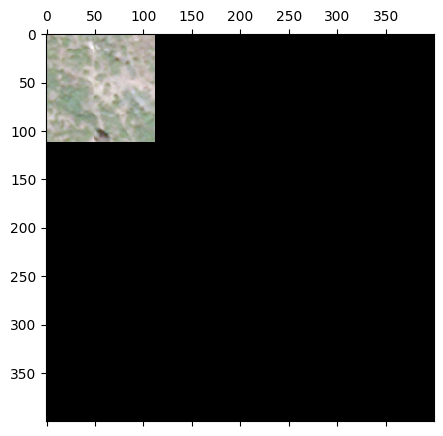

In [27]:
from matplotlib import pyplot as plt

def plot_chips(chips):
    nrows = len(chips)
    fig, axes = plt.subplots(nrows=nrows, figsize=(5, nrows*10))

    for i, chip in enumerate(chips):
        
        colors_mins = chip.reshape(-1, chip.shape[-1]).min(axis=0)
        colors_maxs = chip.reshape(-1, chip.shape[-1]).max(axis=0)
        chip_normalized = (chip - colors_mins) / (colors_maxs - colors_mins)
        if nrows > 1:
            axes[i].matshow(chip_normalized)
        else:
            axes.matshow(chip_normalized)
    plt.show()
plot_chips([chip])

In [28]:
from PIL import Image

def save_img(chip, outp):
    c = Image.fromarray(chip)
    c.save(outp)
save_img(chip, 'testchip.jpg')

In [29]:
rasterdims = raster_source.shape
w, h, _ = rasterdims

In [30]:
import numpy as np

width = 400
height = 400

chipw_idxs = list(np.random.randint(0, w / width , size=10))
chiph_idxs = list(np.random.randint(0, h / height , size=10))
print([(x,y) for x,y in zip(chipw_idxs, chiph_idxs)])

[(0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (0, 0), (0, 0)]


[(400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3), (400, 400, 3)]


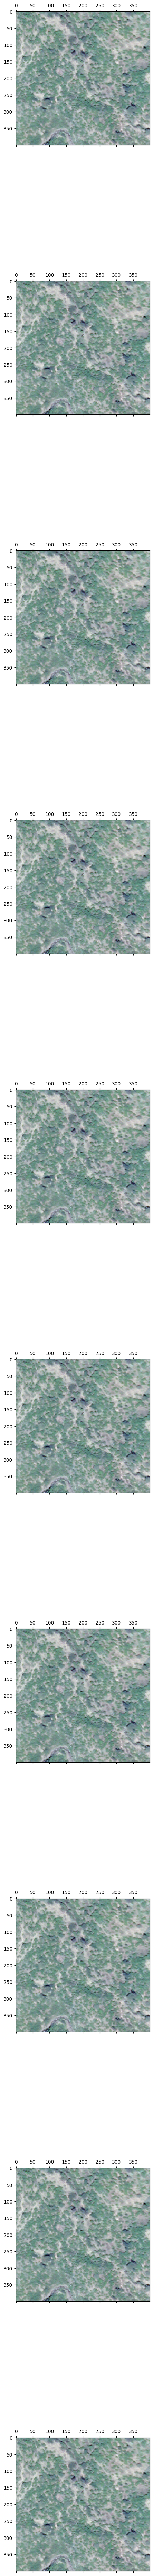

In [31]:
chips = [
    raster_source[x*width:(x+1)*width, y*height:(y+1)*height]
    for x,y in zip(chipw_idxs, chiph_idxs)
]
print([c.shape for c in chips])
plot_chips(chips)

We can even do slightly fancier indexing. The example below reads a 400x400 chip from the the first band in the raster, subsampled to 100x100.

In [15]:
!mkdir annimgs_test1

In [16]:
for i, chip in enumerate(chips):
    save_img(chip, f'annimgs_test1/chip{i}.jpg')

chip.shape: (100, 100, 1)


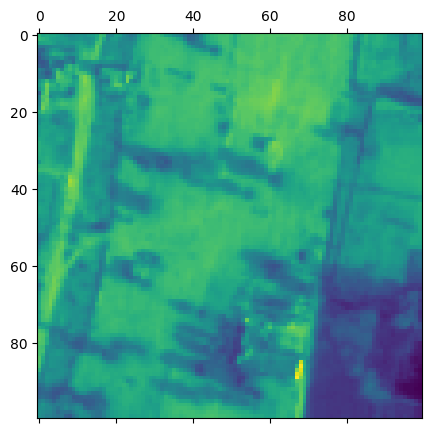

In [17]:
chip = raster_source[400:800:4, 400:800:4, [0]]
print('chip.shape:', chip.shape)

fig, ax = plt.subplots(figsize=(5, 5))
ax.matshow(chip)
plt.show()

In [18]:
from rastervision.core.box import Box

chip = raster_source.get_chip(
    window=Box(ymin=400, xmin=400, ymax=800, xmax=800),
    out_shape=(100, 100),
    bands=[0])
chip.shape

(100, 100, 1)

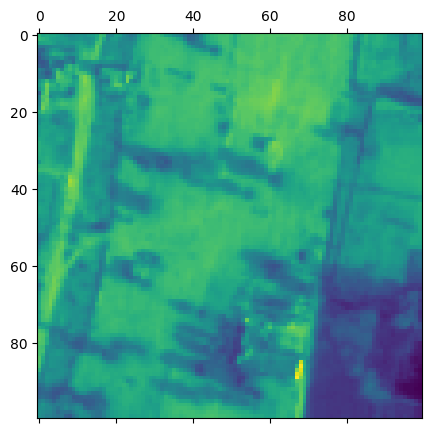

In [19]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.matshow(chip)
plt.show()

<hr style="border:2px solid gray">

## Transforming rasters using `RasterTransformer`s

---

### `MinMaxTransformer`

In [20]:
from rastervision.core.data import RasterioSource, MinMaxTransformer

img_uri = 's3://azavea-research-public-data/raster-vision/examples/spacenet/RGB-PanSharpen_AOI_2_Vegas_img205.tif'
raster_source = RasterioSource(img_uri, allow_streaming=True)

raster_source_normalized = RasterioSource(
    img_uri, 
    allow_streaming=True, 
    raster_transformers=[MinMaxTransformer()])

RasterioIOError: AWS_SECRET_ACCESS_KEY and AWS_NO_SIGN_REQUEST configuration options not defined, and /Users/isabellopez/.aws/credentials not filled

In [ ]:
from matplotlib import pyplot as plt

chip = raster_source_normalized[:400, :400]

fig, ax = plt.subplots(figsize=(5, 5))
ax.matshow(chip)
plt.show()

---

### `StatsTransformer`

In [10]:
from rastervision.core import RasterStats
from rastervision.core.data import RasterioSource, StatsTransformer

img_uri = 's3://azavea-research-public-data/raster-vision/examples/spacenet/RGB-PanSharpen_AOI_2_Vegas_img205.tif'
raster_source = RasterioSource(img_uri, allow_streaming=True)

stats_transformer = StatsTransformer.from_raster_sources(
    raster_sources=[raster_source],
    max_stds=3)

raster_source_normalized = RasterioSource(
    img_uri, 
    allow_streaming=True, 
    raster_transformers=[stats_transformer])

Analyzing chips: 0it [00:00, ?it/s]

In [11]:
stats_transformer.means, stats_transformer.stds

(array([[[577.23597778, 716.4319    , 519.44995556]]]),
 array([[[351.254233  , 342.98780916, 200.60693   ]]]))

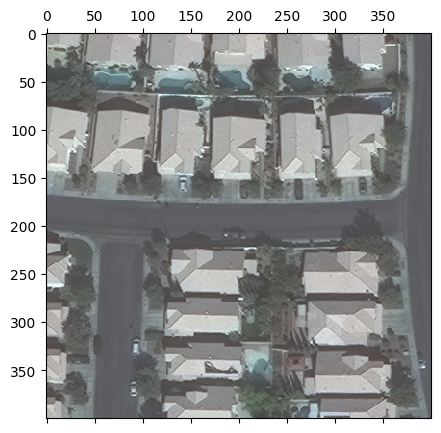

In [12]:
from matplotlib import pyplot as plt

chip_normalized = raster_source_normalized[:400, :400]

fig, ax = plt.subplots(figsize=(5, 5))
ax.matshow(chip_normalized)
plt.show()

To get a closer look at StatsTransformer's work, we can visualize each band's pixel intensity distributions with and without it:

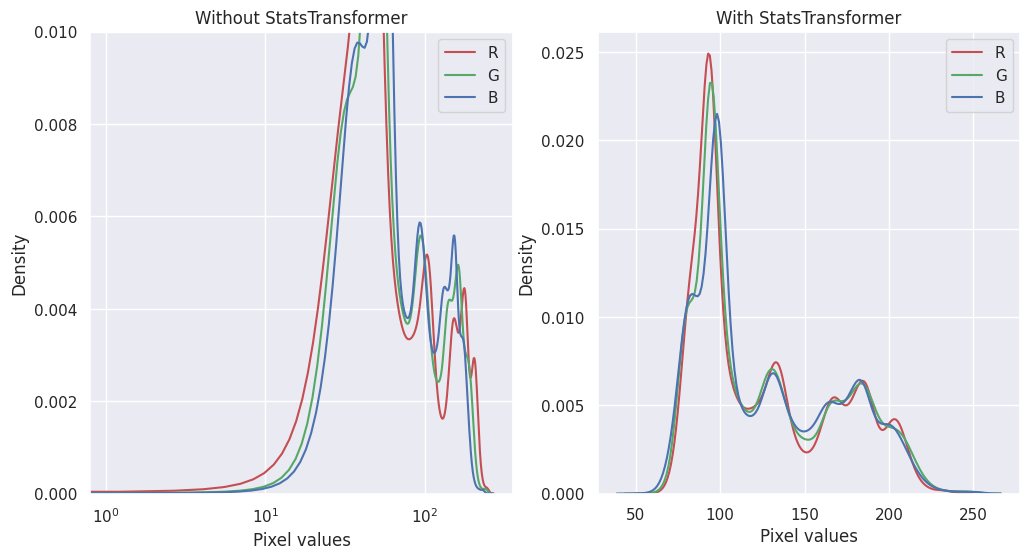

In [13]:
import seaborn as sns
sns.reset_defaults()
sns.set_theme()

band_names = 'RGB'

fig, (ax_l, ax_r) = plt.subplots(1, 2, squeeze=True, figsize=(12, 6))

# left
for i in range(chip.shape[-1]):
    sns.kdeplot(chip[..., i].flat, ax=ax_l, c=band_names[i].lower(), label=band_names[i])
ax_l.set_xscale('log')
ax_l.set_ylim((0, 0.01))
ax_l.set_xlabel('Pixel values')
ax_l.legend()
ax_l.set_title('Without StatsTransformer')

# right
for i in range(chip_normalized.shape[-1]):
    sns.kdeplot(
        chip_normalized[..., i].flat, ax=ax_r, c=band_names[i].lower(), label=band_names[i])
ax_r.set_xlabel('Pixel values')
ax_r.legend()
ax_r.set_title('With StatsTransformer')

plt.show()
sns.reset_defaults()

<hr style="border:2px solid gray">

## Subsetting and reordering bands

Dealing with multi-band imagery is a commonn use case in the GIS domain. All parts of Raster Vision work seamlessly with arbitrary number of bands.

The following example shows how we can use `RasterioSource` to sample 6 specific channels from a 191-band hyperspectral image.

Data from: https://engineering.purdue.edu/~biehl/MultiSpec/hyperspectral.html

In [14]:
!wget "http://cobweb.ecn.purdue.edu/~biehl/Hyperspectral_Project.zip"
!apt-get install unzip
!unzip "Hyperspectral_Project.zip"

There are 2 ways to do this. We can either instantiate a `RasterioSource` like normal and sample the subset of bands using array indexing...

In [15]:
from rastervision.core.data import RasterioSource, MinMaxTransformer

img_uri = 'Hyperspectral_Project/dc.tif'
raster_source_hsi = RasterioSource(img_uri)

raster_source_hsi.shape, raster_source_hsi.dtype

((1280, 307, 191), dtype('int16'))

In [16]:
chip = raster_source_hsi[:100, :100, [10, 30, 50, 70, 110, 130]]
chip.shape

(100, 100, 6)

... Or we can specify the `channel_order` param while instantiating the `RasterioSource`, which will automatically restrict all sampled chips to these bands.

In [17]:
raster_source_hsi = RasterioSource(
    img_uri, 
    channel_order=[10, 30, 50, 70, 110, 130],
    raster_transformers=[MinMaxTransformer()])

raster_source_hsi.shape, raster_source_hsi.dtype

((1280, 307, 6), dtype('uint8'))

In [18]:
chip = raster_source_hsi[200:500, :]
chip.shape

(300, 307, 6)

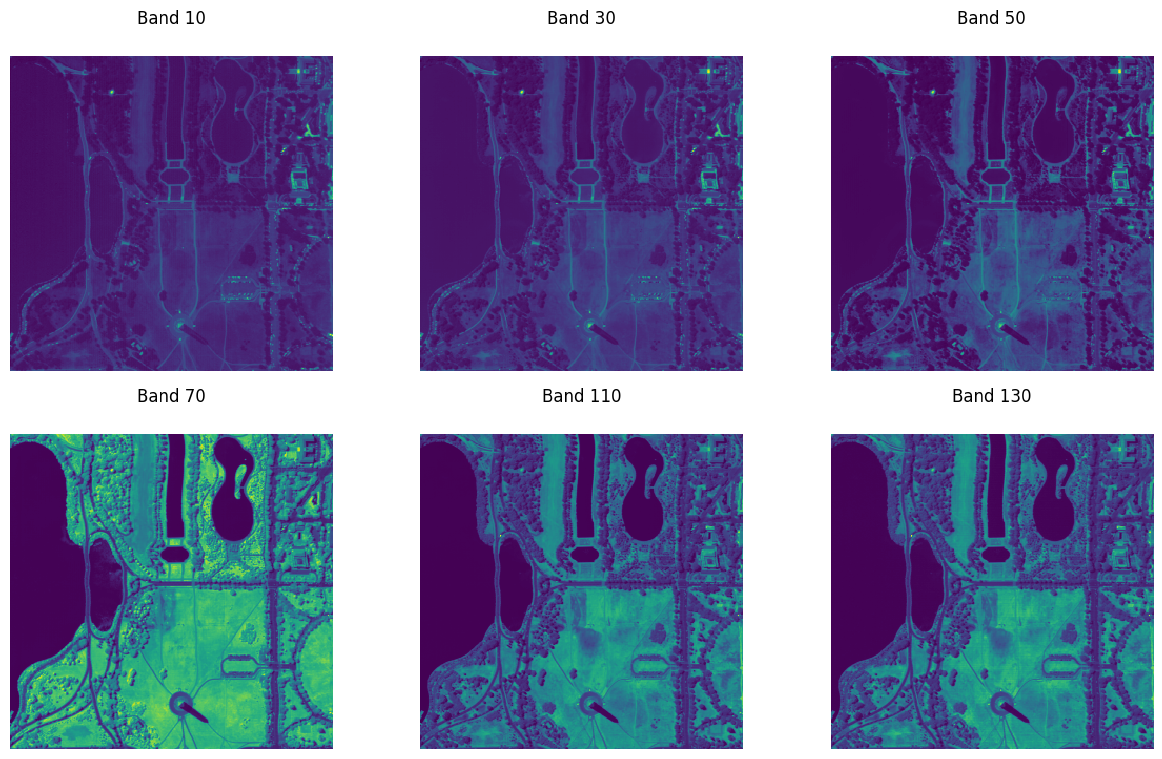

In [19]:
fig, axs = plt.subplots(2, 3, squeeze=True, figsize=(15, 9))

for i, (ax, ch) in enumerate(zip(axs.flat, raster_source_hsi.channel_order)):
    ax.matshow(chip[..., i])
    ax.set_title(f'Band {ch}')
    ax.axis('off')
plt.show()

---

## Combining bands from different files using `MultiRasterSource`

The following example combines RGB, SWIR, and SAR bands into a single 8-band ``RasterSource``.

Data from: [Cloud to Street - Microsoft flood dataset](https://mlhub.earth/data/c2smsfloods_v1)

In [20]:
uri_seninel_2_rgb = 'https://radiantearth.blob.core.windows.net/mlhub/c2smsfloods/chips/e7d1917e-c069-45cf-a392-42e24aa2f4ac/s2/S2A_MSIL1C_20201022T100051_N0209_R122_T33UXP_20201022T111023_07680-00512/RGB.png'
uri_seninel_2_swir = 'https://radiantearth.blob.core.windows.net/mlhub/c2smsfloods/chips/e7d1917e-c069-45cf-a392-42e24aa2f4ac/s2/S2A_MSIL1C_20201022T100051_N0209_R122_T33UXP_20201022T111023_07680-00512/SWIR.png'
uri_seninel_1_vh = 'https://radiantearth.blob.core.windows.net/mlhub/c2smsfloods/chips/e7d1917e-c069-45cf-a392-42e24aa2f4ac/s1/S1B_IW_GRDH_1SDV_20201020T164222_20201020T164247_023899_02D6C4_35D8_07680-00512/VH.tif'
uri_seninel_1_vv = 'https://radiantearth.blob.core.windows.net/mlhub/c2smsfloods/chips/e7d1917e-c069-45cf-a392-42e24aa2f4ac/s1/S1B_IW_GRDH_1SDV_20201020T164222_20201020T164247_023899_02D6C4_35D8_07680-00512/VV.tif'

First, we create `RasterSource`s for each individual source.

In [21]:
from rastervision.core.data import RasterioSource, MultiRasterSource, MinMaxTransformer

rs_sentinel_2_rgb = RasterioSource(uri_seninel_2_rgb, allow_streaming=True)
rs_sentinel_2_swir = RasterioSource(uri_seninel_2_swir, allow_streaming=True)

rs_seninel_1_vh = RasterioSource(uri_seninel_1_vh, allow_streaming=True, raster_transformers=[MinMaxTransformer()])
rs_seninel_1_vv = RasterioSource(uri_seninel_1_vv, allow_streaming=True, raster_transformers=[MinMaxTransformer()])

print('rs_sentinel_2_rgb', rs_sentinel_2_rgb.shape, rs_sentinel_2_rgb.dtype)
print('rs_sentinel_2_swir', rs_sentinel_2_swir.shape, rs_sentinel_2_swir.dtype)
print('rs_seninel_1_vh', rs_seninel_1_vh.shape, rs_seninel_1_vh.dtype)
print('rs_seninel_1_vv', rs_seninel_1_vv.shape, rs_seninel_1_vv.dtype)

rs_sentinel_2_rgb (512, 512, 3) uint8
rs_sentinel_2_swir (512, 512, 3) uint8
rs_seninel_1_vh (512, 512, 1) uint8
rs_seninel_1_vv (512, 512, 1) uint8


In [22]:
raster_sources = [
    rs_sentinel_2_rgb,
    rs_sentinel_2_swir,
    rs_seninel_1_vh,
    rs_seninel_1_vv
]

raster_source_multi = MultiRasterSource(
    raster_sources=raster_sources, primary_source_idx=0)

raster_source_multi.shape, raster_source_multi.dtype

((512, 512, 8), dtype('uint8'))

In [23]:
chip = raster_source_multi[:, :]
chip.shape

(512, 512, 8)

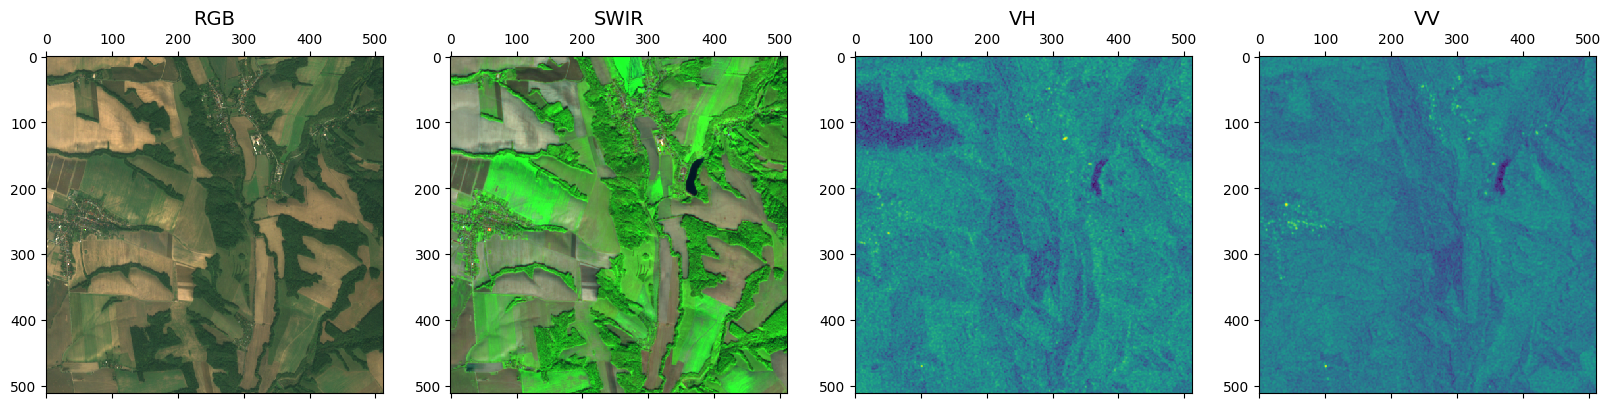

In [24]:
from matplotlib import pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
(ax_rgb, ax_swir, ax_vh, ax_vv) = axs.flat

ax_rgb.matshow(chip[..., :3])
ax_rgb.set_title('RGB', fontsize=14)
ax_swir.matshow(chip[..., 3:6])
ax_swir.set_title('SWIR', fontsize=14)
ax_vh.matshow(chip[..., 6])
ax_vh.set_title('VH', fontsize=14)
ax_vv.matshow(chip[..., 7])
ax_vv.set_title('VV', fontsize=14)

plt.show()

<hr style="border:2px solid gray">

## Cropping the extent

Sometimes you might want to crop a `RasterSource`. For example, if you want to use one part of it for training and another for validation.

The following example shows how we can crop out the top 200 pixels and left 200 pixels of the full raster.

In [25]:
from rastervision.core.data import RasterioSource, MinMaxTransformer
from rastervision.core.box import Box

img_uri = 's3://azavea-research-public-data/raster-vision/examples/spacenet/RGB-PanSharpen_AOI_2_Vegas_img205.tif'
raster_source_cropped = RasterioSource(
    img_uri, 
    allow_streaming=True, 
    extent=Box(200, 200, 650, 650),
    raster_transformers=[MinMaxTransformer()])

raster_source_cropped.shape, raster_source_cropped.dtype

((450, 450, 3), dtype('uint8'))

(400, 400, 3)


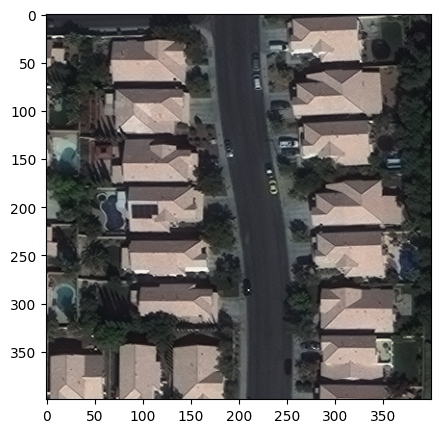

In [26]:
from rastervision.core.box import Box
from matplotlib import pyplot as plt

chip = raster_source_cropped[:400, :400]
print(chip.shape)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(chip)
plt.show()